# Radiant Intensity

`optiland.analysis.RadiantIntensity` groups traced rays by their outgoing direction,
rather than by where they hit the image plane. This example uses the on-axis field
of the Cooke triplet at its primary wavelength (0.55 µm).

We use **relative mode**: the stored map contains summed ray weights per angular
bin, and the plots are normalized to their peak. These weights are not calibrated
power, so this example does **not** report W/sr. Absolute radiant intensity requires
ray powers in watts and `use_absolute_units=True`, which also divides each bin's
power by its solid angle.

In [1]:
from io import BytesIO

import matplotlib.pyplot as plt
from IPython.display import Image, display

from optiland.analysis import RadiantIntensity
from optiland.samples.objectives import CookeTriplet


def show_figure(fig):
    """Embed a figure even when running with MPLBACKEND=Agg."""
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)


lens = CookeTriplet()

## Choose the angular window and sampling

`reference_surface_index=-1` uses directions at the image surface. X and Y angles
are the projections `atan2(L, N)` and `atan2(M, N)`, in degrees, where L, M and N
are direction cosines. 

They are not positions in millimeters or the polar and azimuthal angles of spherical coordinates. 
X angle is the angle between the ray's projection and the Z axis in the XZ plane, 
and Y angle is the angle between the ray's projection and the Z axis in the YZ plane.

The window below covers −8° to +8° in both directions. Rays outside that window
are not binned. More bins reveal finer structure but require more rays to avoid
sparse bins. For `distribution="hexapolar"`, `num_rays=80` means **80 pupil rings**,
not 80 individual rays: the deterministic pattern contains 19,441 launch points.

In [2]:
intensity = RadiantIntensity(
    lens,
    fields=[(0.0, 0.0)],
    wavelengths="primary",
    distribution="hexapolar",
    num_rays=80,
    reference_surface_index=-1,
    num_angular_bins_X=41,
    num_angular_bins_Y=31,
    angle_X_min=-8.0,
    angle_X_max=8.0,
    angle_Y_min=-8.0,
    angle_Y_max=8.0,
    use_absolute_units=False,
)

## Read the map and central profile

The color represents the summed weight in each angular bin divided by the largest
bin weight in this field/wavelength map. The peak is 1; a value of 0.5 means half
the peak bin weight, not half the total power. Empty bins have value zero. The
right-hand curve is the X-angle profile through the central Y-angle bin.

In relative mode, `normalize=True` changes only the display: `intensity.data`
still holds unnormalized bin weights. Sampling and bin size affect the pattern;
it is not an image-plane irradiance map or a calibrated per-steradian distribution.

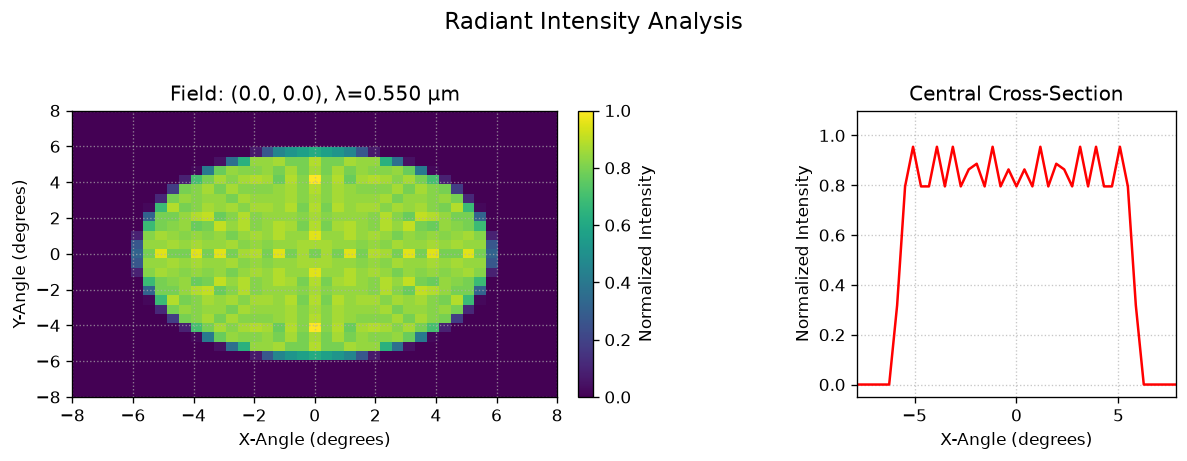

In [3]:
fig, axes = intensity.view(normalize=True, cmap="viridis", figsize=(10, 4), show=False)
fig.subplots_adjust(wspace=0.6)
show_figure(fig)

## Select a different cross-section

`cross_section=("cross-y", -1)` plots Y angle at the central X-angle bin; −1
selects the central bin. Use `("cross-x", index)` to select a fixed Y-angle bin
instead. Normalization still uses the peak of the whole map, so an arbitrary
slice need not reach 1.

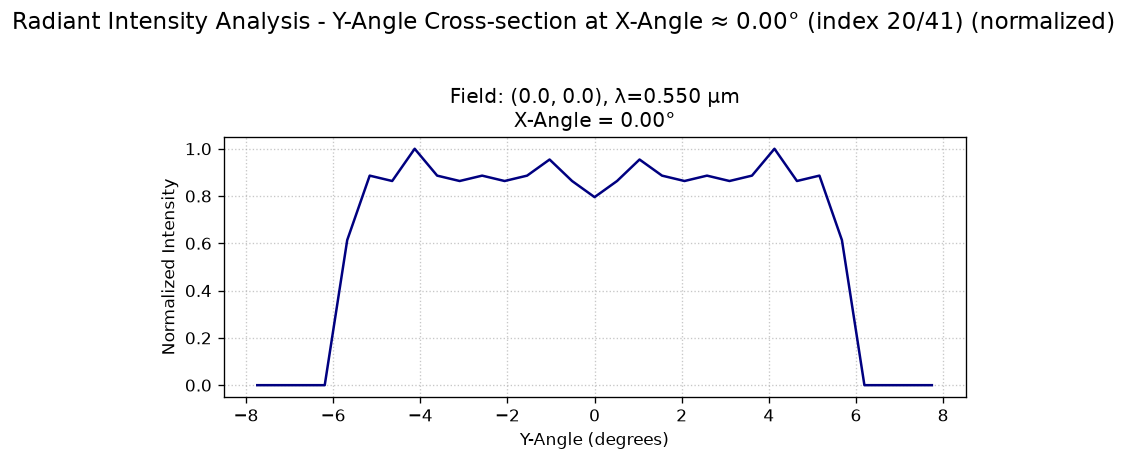

In [4]:
fig, axes = intensity.view(
    cross_section=("cross-y", -1),
    normalize=True,
    cross_section_color="navy",
    figsize=(7, 4),
    show=False,
)
show_figure(fig)